# AA3 · Parcial II · Cuaderno 3: Transformers

**Alumno:** Edgar Mauricio Trejo Delgado

**Datos:** Temática opcional · mesa de ayuda de una universidad ficticia. Mensajes sintéticos generados con plantillas y una prueba escrita aparte, con otro estilo. Todo es ficticio.

**Opción:** BETO

## 1. Datos
Clasificar cada mensaje de un estudiante en **5 clases**: `inscripciones`, `pagos_y_becas`, `constancias`, `soporte_tecnico` y `urgencia_campus`. La **clase crítica** es `urgencia_campus`: es la que no se puede perder.

- **Entrenamiento y validación:** 120 mensajes sintéticos por clase (600 en total), generados con plantillas y ruido realista (minúsculas, sin acentos, sin «¿», erratas, saludos). Se dividen 80/20 con semilla, así que quedan **96 por clase para entrenar** (≥ 50).
- **Prueba:** 75 mensajes (**15 por clase**) **escritos aparte a mano**, con otro estilo: faltas de ortografía, abreviaturas («xq», «q», «pa»), mensajes con **dos temas a la vez**, urgencias en tercera persona y palabras que engañan (una urgencia que menciona Moodle o la colegiatura, una constancia que «urge»). No salen del generador.

In [1]:
import os
import sys
import gc
import time
import random
import importlib.util

EN_COLAB = importlib.util.find_spec("google.colab") is not None
os.environ["USE_TF"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import torch
import transformers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

SEED = 42
transformers.set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
GPU = torch.cuda.is_available()
DIR_MODELOS = os.path.join("modelos", "C3")
os.makedirs(DIR_MODELOS, exist_ok=True)
pd.set_option("display.max_colwidth", 120)

print(f"Entorno: {'Google Colab' if EN_COLAB else 'Local'} · PyTorch {torch.__version__} · transformers {transformers.__version__}")
print(f"GPU: {torch.cuda.get_device_name(0) if GPU else 'NO (en Colab: Entorno de ejecución → Cambiar tipo de entorno → T4)'}")

CLASES = ["inscripciones", "pagos_y_becas", "constancias", "soporte_tecnico", "urgencia_campus"]
CRITICA = "urgencia_campus"
registro = {}

def metricas(y_real, y_pred):
    return {"Exactitud": accuracy_score(y_real, y_pred),
            "F1 macro": f1_score(y_real, y_pred, average="macro", labels=CLASES, zero_division=0),
            "Sensibilidad urgencia": recall_score(y_real, y_pred, labels=[CRITICA], average="macro", zero_division=0)}

def registrar(nombre, prueba, val=None, segundos=0.0):
    fila = {f"{k} (prueba)": v for k, v in metricas(*prueba).items()}
    fila["Exactitud (val)"] = accuracy_score(*val) if val is not None else np.nan
    fila["Entrenamiento (s)"] = segundos
    registro[nombre] = fila

def graficar_confusion(y_real, y_pred, titulo):
    M = confusion_matrix(y_real, y_pred, labels=CLASES)
    fig, ax = plt.subplots(figsize=(6.4, 5.2))
    ax.imshow(M, cmap="Blues")
    ax.set_xticks(range(len(CLASES)), CLASES, rotation=35, ha="right")
    ax.set_yticks(range(len(CLASES)), CLASES)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

Entorno: Google Colab · PyTorch 2.11.0+cu130 · transformers 5.22.0
GPU: Tesla T4


In [2]:
# Generador del dataset SINTÉTICO (entrenamiento y validación). Determinista con la semilla.
MATERIAS = ["Cálculo II", "Programación Orientada a Objetos", "Física I", "Estadística", "Inglés V", "Bases de Datos",
            "Ética Profesional", "Álgebra Lineal", "Redes Neuronales", "Contabilidad", "Química General"]
SEMESTRES = ["tercero", "cuarto", "quinto", "sexto", "séptimo", "octavo"]
CUANDO = ["mañana", "el lunes", "esta semana", "la próxima semana", "hoy", "el viernes", "en enero", "antes del día 15"]
CONCEPTOS = ["la colegiatura", "la inscripción", "el examen extraordinario", "la credencial", "el seguro estudiantil",
             "la reinscripción", "el curso de verano"]
BECAS = ["beca académica", "beca deportiva", "beca socioeconómica", "beca de excelencia", "beca cultural"]
DOCS = ["una constancia de estudios", "mi kárdex", "una carta de pasante", "una constancia de inscripción",
        "mi historial académico", "una carta de buena conducta", "un certificado parcial", "una boleta oficial"]
PARA = ["para el viernes", "para el IMSS", "para mi trabajo", "para el servicio social", "para un trámite de visa",
        "para el seguro de mis papás", "para una beca del gobierno", "para mis prácticas profesionales"]
PLATAFORMAS = ["Moodle", "el correo institucional", "el portal de alumnos", "el wifi del campus", "Teams",
               "la app de la universidad", "la biblioteca digital"]
PROBLEMAS = ["dice que mi contraseña está mal", "no carga", "me marca error", "se me bloqueó la cuenta",
             "no me llegan las notificaciones", "se cierra solo", "no aparece mi curso", "está muy lento"]
QUIEN = ["un compañero", "una compañera", "un maestro", "mi amigo", "un señor de mantenimiento",
         "una alumna de primer semestre", "alguien", "una maestra"]
LUGARES = ["en el laboratorio", "en la biblioteca", "en la cafetería", "en el estacionamiento", "en el edificio C",
           "en las canchas", "en el salón 204", "en el baño del segundo piso", "en el auditorio"]
EVENTOS = ["se desmayó", "se cayó por las escaleras y no se puede levantar", "está convulsionando",
           "tiene una reacción alérgica fuerte", "se cortó la mano y está sangrando mucho", "no puede respirar bien",
           "se golpeó la cabeza y está desorientado", "se quemó con un químico"]
PELIGROS = ["huele mucho a gas", "hay humo saliendo de un salón", "se está incendiando un contenedor",
            "hay un cable eléctrico echando chispas", "se derramó un químico y hay vapores",
            "hay una persona agresiva amenazando a los alumnos"]

PLANTILLAS = {
    "inscripciones": ["No me deja inscribir las materias de {semestre}", "El sistema no me deja dar de alta {materia}",
                      "¿Cuándo abren las inscripciones de {semestre} semestre?", "Quiero dar de baja {materia}, ¿cómo le hago?",
                      "{materia} ya no tiene cupo, ¿van a abrir otro grupo?", "Necesito cambiarme de grupo en {materia}",
                      "¿Puedo inscribir {materia} si debo la seriada?", "Mi horario de inscripción es {cuando} pero no aparece {materia}",
                      "¿Cuántas materias puedo inscribir como máximo en {semestre}?", "Me inscribí a {materia} por error, quiero cambiarla",
                      "No aparece mi carga académica de {semestre}", "¿El periodo de altas y bajas es {cuando}?"],
    "pagos_y_becas": ["Ya pagué {concepto} y me sigue saliendo adeudo", "¿Cuándo es la fecha límite para pagar {concepto}?",
                      "Quiero solicitar la {beca}, ¿qué requisitos piden?", "No me aplicaron el descuento de mi {beca}",
                      "¿Puedo pagar {concepto} en parcialidades?", "Me cobraron dos veces {concepto}",
                      "¿Cuándo sale el resultado de la {beca}?", "Necesito la referencia bancaria para pagar {concepto}",
                      "Me quitaron la {beca}, ¿cómo apelo?", "¿Me pueden dar factura de {concepto}?",
                      "Pagué {concepto} {cuando} y no se refleja", "¿Cuánto cuesta {concepto} este semestre?"],
    "constancias": ["Necesito {doc} {para}", "¿Cómo solicito {doc}?", "¿Cuánto tarda en salir {doc}?",
                    "Pedí {doc} hace una semana y no me llega", "¿Me pueden mandar {doc} en digital?",
                    "Ocupo {doc} con sello {para}", "¿Dónde recojo {doc}?", "Quisiera tramitar {doc} {para}",
                    "¿Tiene costo sacar {doc}?", "Me piden {doc} {para}, ¿a quién se lo pido?"],
    "soporte_tecnico": ["No puedo entrar a {plataforma}, {problema}", "Desde ayer {plataforma} {problema}",
                        "Olvidé mi contraseña de {plataforma}", "¿Cómo reseteo mi contraseña de {plataforma}?",
                        "No me deja subir la tarea a {plataforma}", "¿Quién me ayuda con {plataforma}? {problema}",
                        "No puedo conectarme a {plataforma} desde mi laptop", "Se me borró la entrega en {plataforma}",
                        "Tengo problemas con {plataforma}: {problema}"],
    "urgencia_campus": ["{quien} {evento} {lugar}", "Urgente: {quien} {evento} {lugar}", "Ayuda, {peligro} {lugar}",
                        "{peligro} {lugar}, ¿a quién llamo?", "Manden a alguien {lugar}, {quien} {evento}",
                        "Por favor llamen a enfermería, {quien} {evento}", "Es una emergencia, {peligro} {lugar}",
                        "{lugar} {peligro}, vengan rápido"],
}
SALUDOS = ["", "", "", "Hola, ", "Buenas tardes, ", "Buen día, ", "Buenas, ", "Hola buenas noches, "]
CIERRES = ["", "", "", " gracias", " por favor", " porfa", ", saludos", " 🙏", " de antemano gracias"]

def _sin_acentos(t):
    return t.translate(str.maketrans("áéíóúÁÉÍÓÚ", "aeiouAEIOU"))

def _ruido(t, rng):
    if rng.random() < 0.35:
        t = t.lower()
    if rng.random() < 0.30:
        t = _sin_acentos(t)
    if rng.random() < 0.40:
        t = t.replace("¿", "")
    if rng.random() < 0.10 and len(t) > 12:   # una errata: intercambia dos letras
        i = rng.randrange(1, len(t) - 2)
        t = t[:i] + t[i + 1] + t[i] + t[i + 2:]
    return " ".join(t.split())

def generar(n_por_clase=120, semilla=SEED):
    rng = random.Random(semilla)
    datos = []
    for clase in CLASES:
        vistos = set()
        while len(vistos) < n_por_clase:
            texto = rng.choice(PLANTILLAS[clase]).format(
                materia=rng.choice(MATERIAS), semestre=rng.choice(SEMESTRES), cuando=rng.choice(CUANDO),
                concepto=rng.choice(CONCEPTOS), beca=rng.choice(BECAS), doc=rng.choice(DOCS), para=rng.choice(PARA),
                plataforma=rng.choice(PLATAFORMAS), problema=rng.choice(PROBLEMAS), quien=rng.choice(QUIEN),
                lugar=rng.choice(LUGARES), evento=rng.choice(EVENTOS), peligro=rng.choice(PELIGROS))
            texto = " ".join(texto.split())
            texto = texto[0].upper() + texto[1:]
            texto = _ruido(rng.choice(SALUDOS) + texto + rng.choice(CIERRES), rng)
            if texto not in vistos:
                vistos.add(texto)
                datos.append((texto, clase))
    rng.shuffle(datos)
    return datos

datos = generar()
print(f"Sintéticos: {len(datos)} mensajes")

Sintéticos: 600 mensajes


In [3]:
# PRUEBA escrita aparte, a mano y con otro estilo (no sale del generador). Todo es ficticio.
PRUEBA = [
    # inscripciones (15)
    ("oigan no puedo meter calculo 2 me sale q no tengo la seriada pero ya la pase", "inscripciones"),
    ("se me paso la fecha de altas y bajas, todavia puedo meter una optativa?", "inscripciones"),
    ("Buenas noches, quiero cambiarme del grupo de la mañana al de la tarde en estadística porque entro a trabajar", "inscripciones"),
    ("el portal dice 'sin horario de inscripcion asignado' y mañana empiezan clases", "inscripciones"),
    ("como le hago para recursar una materia que repobré", "inscripciones"),
    ("Me pueden abrir otro grupo de bases de datos?? ya se lleno y lo necesito para titularme", "inscripciones"),
    ("quiero dar de vaja física 1 antes de que me afecte el promedio", "inscripciones"),
    ("No me aparece ninguna materia para elegir este semestre, solo me sale mi horario vacío", "inscripciones"),
    ("Puedo llevar 8 materias o el máximo son 7?", "inscripciones"),
    ("Mi amigo y yo queremos quedar en el mismo grupo de inglés, se puede hacer el cambio?", "inscripciones"),
    ("voy de intercambio el otro semestre, cómo dejo apartadas mis materias?", "inscripciones"),
    ("Me inscribieron en una materia que no elegí (Contabilidad), quítenla porfa", "inscripciones"),
    ("cuando son las inscripciones para verano?", "inscripciones"),
    ("Hola!! soy de nuevo ingreso y no entiendo cómo armar mi horario", "inscripciones"),
    ("ya pagué la reinscripción, ahora cómo escojo mis materias de quinto?", "inscripciones"),
    # pagos_y_becas (15)
    ("ya deposite lo de la colegiatura desde el lunes y en el sistema sigo debiendo", "pagos_y_becas"),
    ("me pueden explicar xq me cobraron recargo si pague a tiempo", "pagos_y_becas"),
    ("mi papá se quedó sin trabajo, hay algún apoyo para no dejar la carrera?", "pagos_y_becas"),
    ("renové la beca pero este mes me llegó el cobro completo", "pagos_y_becas"),
    ("aceptan pago con tarjeta de crédito a meses?", "pagos_y_becas"),
    ("Necesito factura de la colegiatura a nombre de mi mamá, a qué correo la pido?", "pagos_y_becas"),
    ("salieron los resultados de las becas deportivas? juego en el equipo de futbol", "pagos_y_becas"),
    ("cuanto sale el extra de calculo", "pagos_y_becas"),
    ("Me bajaron el porcentaje de beca de 50 a 30 sin avisar, ¿con quién hablo?", "pagos_y_becas"),
    ("¿Hasta cuándo tengo para pagar sin recargos?", "pagos_y_becas"),
    ("no encuentro la referencia para pagar en el oxxo", "pagos_y_becas"),
    ("Mi beca me la quitaron por un 7.9 de promedio, hay segunda oportunidad?", "pagos_y_becas"),
    ("el seguro estudiantil ya viene incluido en lo que pagué o es aparte?", "pagos_y_becas"),
    ("pague la credencial nueva y todavia no me la dan, me regresan el dinero o qué onda", "pagos_y_becas"),
    ("Moodle me dice que tengo adeudo y por eso no veo mis calificaciones, pero ya pagué", "pagos_y_becas"),
    # constancias (15)
    ("ocupo mi kardex sellado pa mañana temprano, se puede?", "constancias"),
    ("Buen día, la constancia de estudios trae el promedio o eso es otro papel?", "constancias"),
    ("pedi una carta para el servicio social hace 2 semanas y nada", "constancias"),
    ("Necesito comprobar que estoy inscrito para que el IMSS me siga dando servicio", "constancias"),
    ("Me pueden dar un documento que diga que curso el 5to semestre? Es para mi visa", "constancias"),
    ("mi constancia salio con mi apellido mal escrito, me la corrigen?", "constancias"),
    ("La constancia digital tiene validez o tiene que ser en papel con firma?", "constancias"),
    ("Cuánto cuesta un certificado parcial y cuántos días tarda?", "constancias"),
    ("para el trabajo me piden un historial académico, dónde lo saco", "constancias"),
    ("hola necesito constancia de inscripción para la beca del gobierno", "constancias"),
    ("Puede recoger mi constancia mi hermana? Yo estoy fuera de la ciudad", "constancias"),
    ("Me urge la carta de pasante, la entrevista es el viernes", "constancias"),
    ("Dónde está la ventanilla de servicios escolares para recoger documentos?", "constancias"),
    ("necesito que me certifiquen las calificaciones del semestre pasado", "constancias"),
    ("Mi aseguradora pide un papel de que soy estudiante de tiempo completo", "constancias"),
    # soporte_tecnico (15)
    ("no me deja entrar al moodle, dice q mi contraseña esta mal y ya la cambie 2 veces", "soporte_tecnico"),
    ("El wifi de la biblio no sirve desde la mañana", "soporte_tecnico"),
    ("subi mi tarea a moodle pero sale como no entregada!! la fecha es hoy", "soporte_tecnico"),
    ("Se me olvidó la contraseña del correo de la uni y el de recuperación ya no lo tengo", "soporte_tecnico"),
    ("teams no me deja entrar a la clase en línea, sale error", "soporte_tecnico"),
    ("la app de la universidad se cierra apenas la abro (tengo android)", "soporte_tecnico"),
    ("Cómo instalo el Office que nos dan gratis?", "soporte_tecnico"),
    ("No me llegan los correos de mis maestros, está fallando el servidor?", "soporte_tecnico"),
    ("Me hackearon el correo institucional y están mandando spam", "soporte_tecnico"),
    ("En el laboratorio de cómputo las computadoras no prenden", "soporte_tecnico"),
    ("el portal de alumnos me saca a cada rato y no puedo ver mis calificaciones", "soporte_tecnico"),
    ("no aparece mi curso de redes neuronales en moodle, ya estoy inscrito", "soporte_tecnico"),
    ("Hay forma de conectar mi celular al wifi del campus? me pide un certificado", "soporte_tecnico"),
    ("Bloquearon mi cuenta por intentos fallidos, me la desbloquean?", "soporte_tecnico"),
    ("La biblioteca digital no me deja descargar artículos, dice acceso denegado", "soporte_tecnico"),
    # urgencia_campus (15)
    ("una chava se desmayó en la fila de la cafe y no reacciona", "urgencia_campus"),
    ("AYUDA en el lab de química se rompió un frasco y huele horrible, nos estamos mareando", "urgencia_campus"),
    ("Mi compañero es diabético y está temblando y sudando, ya no habla bien, estamos en el salón 105", "urgencia_campus"),
    ("hay humo saliendo del cuarto eléctrico del edificio B", "urgencia_campus"),
    ("Se cayó un muchacho de la bici en el estacionamiento, tiene sangre en la cabeza", "urgencia_campus"),
    ("Mi amiga tiene un ataque de pánico y no puede respirar, estamos en el baño de la biblioteca", "urgencia_campus"),
    ("un maestro se puso mal en clase, se agarraba el pecho y se cayó", "urgencia_campus"),
    ("Hay un señor que no es de la escuela siguiendo a unas alumnas en el estacionamiento", "urgencia_campus"),
    ("se esta incendiando el bote de basura junto a las canchas", "urgencia_campus"),
    ("a un compañero le picó una abeja y se le está hinchando la cara, es alérgico", "urgencia_campus"),
    ("Se desmayó una compañera en el laboratorio. Por cierto, a qué hora cierra la biblioteca?", "urgencia_campus"),
    ("estaba en moodle haciendo el examen y el chavo de al lado empezó a convulsionar, qué hacemos", "urgencia_campus"),
    ("Huele a gas en todo el pasillo del tercer piso del edificio C", "urgencia_campus"),
    ("Un alumno se resbaló en la escalera mojada y dice que no siente la pierna", "urgencia_campus"),
    ("ya pagué la colegiatura pero eso no importa ahorita: mi compañera se desmayó en la caja, manden a alguien", "urgencia_campus"),
]

from sklearn.model_selection import train_test_split
textos = [t for t, _ in datos]
etiquetas = [c for _, c in datos]
x_train, x_val, y_train, y_val = train_test_split(textos, etiquetas, test_size=0.2, stratify=etiquetas, random_state=SEED)
x_test = [t for t, _ in PRUEBA]
y_test = [c for _, c in PRUEBA]

conteo = pd.DataFrame({"entrenamiento": pd.Series(y_train).value_counts(), "validación": pd.Series(y_val).value_counts(),
                       "prueba (escrita aparte)": pd.Series(y_test).value_counts()}).loc[CLASES]
assert conteo["entrenamiento"].min() >= 50 and conteo["prueba (escrita aparte)"].min() >= 10
assert not set(x_test) & set(textos), "La prueba no debe compartir mensajes con los sintéticos"
print(f"Entrenamiento: {len(x_train)} · Validación: {len(x_val)} (sintéticos) · Prueba: {len(x_test)} (escrita aparte)")
display(conteo)
print("\nEjemplos sintéticos:")
for t, c in list(zip(x_train, y_train))[:6]:
    print(f"  {c:16s} {t}")
print("\nEjemplos de la prueba:")
for t, c in PRUEBA[::13][:6]:
    print(f"  {c:16s} {t}")

Entrenamiento: 480 · Validación: 120 (sintéticos) · Prueba: 75 (escrita aparte)


,entrenamiento,validación,prueba (escrita aparte)
inscripciones,96,24,15
pagos_y_becas,96,24,15
constancias,96,24,15
soporte_tecnico,96,24,15
urgencia_campus,96,24,15



Ejemplos sintéticos:
  inscripciones    necesito cambiarme de grupo en contabilidad
  urgencia_campus  En el estacionamiento huele mucho a gas, vengan rápido, saludos
  soporte_tecnico  Buen día, No puedo entrar a el wifi del campus, se cierra solo porfa
  inscripciones    hola buenas noches, cuántas materias puedo inscribir como máximo en sexto?, saludos
  urgencia_campus  Un compañero se golpeo la cabeza y esta desorientado en el estacionamiento porfa
  soporte_tecnico  hola, no puedo conectarme a el portal de alumnos desde mi laptop 🙏

Ejemplos de la prueba:
  inscripciones    oigan no puedo meter calculo 2 me sale q no tengo la seriada pero ya la pase
  inscripciones    Hola!! soy de nuevo ingreso y no entiendo cómo armar mi horario
  pagos_y_becas    Mi beca me la quitaron por un 7.9 de promedio, hay segunda oportunidad?
  constancias      hola necesito constancia de inscripción para la beca del gobierno
  soporte_tecnico  No me llegan los correos de mis maestros, está fallando e

## 2. Línea base
Dos líneas base, como en la Práctica 5:
1. **Bigramas:** TF-IDF de unigramas y bigramas + regresión logística (la línea base honesta de la P4 en versión `scikit-learn`).
2. ***Zero-shot*:** un modelo de inferencia de lenguaje natural multilingüe (`MoritzLaurer/mDeBERTa-v3-base-mnli-xnli`) que prueba cada clase como hipótesis, sin ningún dato de entrenamiento.

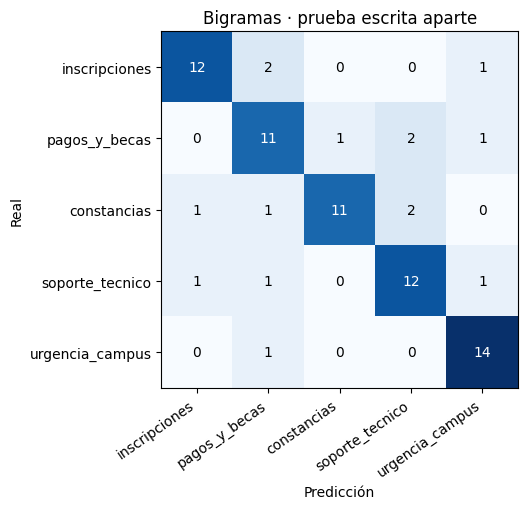

,Exactitud (prueba),F1 macro (prueba),Sensibilidad urgencia (prueba),Exactitud (val),Entrenamiento (s)
Bigramas (TF-IDF + logística),0.8,0.800254,0.933333,1.0,0.148057


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

t0 = time.time()
bigramas = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), LogisticRegression(max_iter=2000, C=10))
bigramas.fit(x_train, y_train)
pred_val_big, pred_test_big = bigramas.predict(x_val), bigramas.predict(x_test)
registrar("Bigramas (TF-IDF + logística)", prueba=(y_test, pred_test_big), val=(y_val, pred_val_big), segundos=time.time() - t0)
graficar_confusion(y_test, pred_test_big, "Bigramas · prueba escrita aparte")
pd.DataFrame(registro).T

In [5]:
from transformers import pipeline

DESCRIPCIONES = {"inscripciones": "inscripción, alta, baja o cambio de materias o de grupo",
                 "pagos_y_becas": "pagos, colegiaturas, adeudos, facturas o becas",
                 "constancias": "solicitud de constancias, kárdex, certificados u otros documentos escolares",
                 "soporte_tecnico": "problemas técnicos con plataformas, contraseñas, correo o internet",
                 "urgencia_campus": "una emergencia de salud o de seguridad en el campus"}
a_clase = {v: k for k, v in DESCRIPCIONES.items()}

t0 = time.time()
zero_shot = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli", device=0 if GPU else -1)
salidas = zero_shot(x_test, candidate_labels=list(DESCRIPCIONES.values()), hypothesis_template="Este mensaje trata de {}.")
pred_test_zs = [a_clase[s["labels"][0]] for s in salidas]
registrar("Zero-shot (mDeBERTa NLI, sin entrenar)", prueba=(y_test, pred_test_zs))
print(f"Clasificó {len(x_test)} mensajes en {time.time() - t0:.0f} s")
del zero_shot
gc.collect()
if GPU:
    torch.cuda.empty_cache()
pd.DataFrame(registro).T

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

... (3 outputs left out)

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Clasificó 75 mensajes en 45 s


,Exactitud (prueba),F1 macro (prueba),Sensibilidad urgencia (prueba),Exactitud (val),Entrenamiento (s)
Bigramas (TF-IDF + logística),0.800000,0.800254,0.933333,1.0,0.148057
"Zero-shot (mDeBERTa NLI, sin entrenar)",0.373333,0.318525,0.000000,NaN,0.000000


## 3. Modelo
**BETO** (`dccuchile/bert-base-spanish-wwm-cased`, 12 capas de *encoder*, ~110 M de parámetros) con una **cabeza de clasificación nueva** de 768 → 5 sobre el token `[CLS]`. Se ajusta **todo** con el `Trainer` de Hugging Face, con los hiperparámetros de la práctica: tasa de aprendizaje de 3 × 10⁻⁵, 4 épocas, lotes de 16 y máximo 64 tokens.

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments

NOMBRE_BETO = "dccuchile/bert-base-spanish-wwm-cased"
REVISION_BETO = "refs/pr/3"   # variante safetensors, como en la práctica
id2label = dict(enumerate(CLASES))
label2id = {v: k for k, v in id2label.items()}
tokenizador = AutoTokenizer.from_pretrained(NOMBRE_BETO)

modelo = AutoModelForSequenceClassification.from_pretrained(NOMBRE_BETO, revision=REVISION_BETO, num_labels=len(CLASES),
                                                            id2label=id2label, label2id=label2id)
cuerpo = sum(p.numel() for n, p in modelo.named_parameters() if not n.startswith("classifier"))
cabeza = sum(p.numel() for n, p in modelo.named_parameters() if n.startswith("classifier"))
print(f"Cuerpo (BETO): {cuerpo / 1e6:.1f} M de parámetros · cabeza nueva: {cabeza:,} parámetros")
print("Tokens de un mensaje:", tokenizador.tokenize(x_test[0]))

class DatasetMensajes(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.codificados = tokenizador(textos, truncation=True, max_length=64)
        self.etiquetas = [label2id[e] for e in etiquetas]
    def __len__(self):
        return len(self.etiquetas)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.codificados.items()}
        item["labels"] = self.etiquetas[i]
        return item

ds_train, ds_val, ds_test = DatasetMensajes(x_train, y_train), DatasetMensajes(x_val, y_val), DatasetMensajes(x_test, y_test)
collator = DataCollatorWithPadding(tokenizador)

def calcular_metricas(eval_pred):
    logits, etiquetas_num = eval_pred
    pred = logits.argmax(axis=-1)
    return {"accuracy": accuracy_score(etiquetas_num, pred), "f1_macro": f1_score(etiquetas_num, pred, average="macro")}

args = TrainingArguments(output_dir=os.path.join(DIR_MODELOS, "beto_mesa_ayuda"), num_train_epochs=4, learning_rate=3e-5,
                         per_device_train_batch_size=16, per_device_eval_batch_size=64, weight_decay=0.01,
                         eval_strategy="epoch", save_strategy="no", logging_strategy="epoch",
                         fp16=GPU and torch.cuda.get_device_capability()[0] >= 7, report_to="none", seed=SEED)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=collator, compute_metrics=calcular_metricas)
t0 = time.time()
trainer.train()
segundos_beto = time.time() - t0

def predecir(ds):
    return [id2label[i] for i in trainer.predict(ds).predictions.argmax(axis=-1)]

pred_val_beto, pred_test_beto = predecir(ds_val), predecir(ds_test)
registrar("BETO ajustado (fine-tuning)", prueba=(y_test, pred_test_beto), val=(y_val, pred_val_beto), segundos=segundos_beto)
print(f"Entrenamiento: {segundos_beto:.0f} s")

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (2 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Cuerpo (BETO): 109.9 M de parámetros · cabeza nueva: 3,845 parámetros
Tokens de un mensaje: ['oiga', '##n', 'no', 'puedo', 'meter', 'calcul', '##o', '2', 'me', 'sale', 'q', 'no', 'tengo', 'la', 'seria', '##da', 'pero', 'ya', 'la', 'pase']


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.077877,0.371622,0.983333,0.983489
2,0.130067,0.017445,1.000000,1.000000
3,0.014469,0.007603,1.000000,1.000000
4,0.009132,0.006512,1.000000,1.000000


Entrenamiento: 17 s


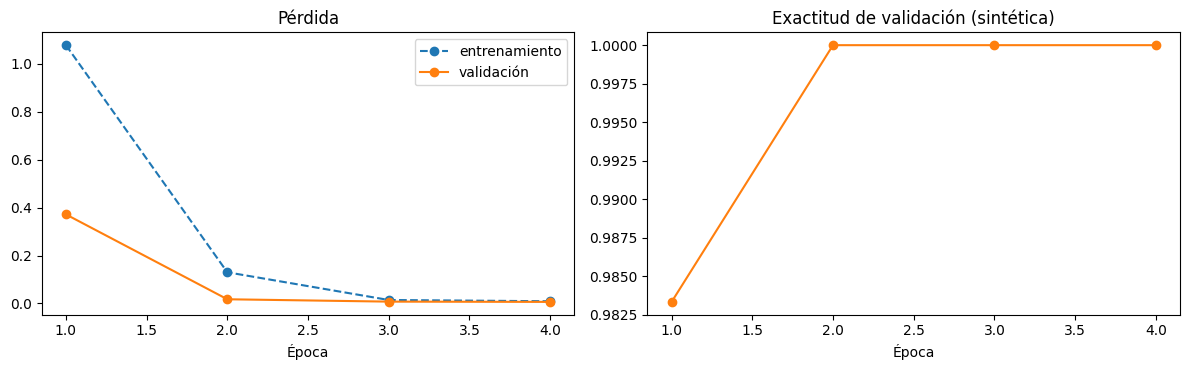

In [7]:
hist = pd.DataFrame(trainer.state.log_history)
perdida_train = hist.dropna(subset=["loss"])[["epoch", "loss"]] if "loss" in hist else None
perdida_val = hist.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy"]]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
if perdida_train is not None:
    ax[0].plot(perdida_train["epoch"], perdida_train["loss"], "o--", label="entrenamiento")
ax[0].plot(perdida_val["epoch"], perdida_val["eval_loss"], "o-", label="validación")
ax[0].set_title("Pérdida")
ax[0].set_xlabel("Época")
ax[0].legend()
ax[1].plot(perdida_val["epoch"], perdida_val["eval_accuracy"], "o-", color="tab:orange")
ax[1].set_title("Exactitud de validación (sintética)")
ax[1].set_xlabel("Época")
plt.tight_layout()
plt.show()

## 4. Resultados
Las **mismas métricas de prueba** para los tres modelos: exactitud, F1 macro y sensibilidad de la clase crítica (`urgencia_campus`). La exactitud de validación es sobre mensajes sintéticos del mismo generador que el entrenamiento; la prueba escrita aparte es la que dice la verdad.

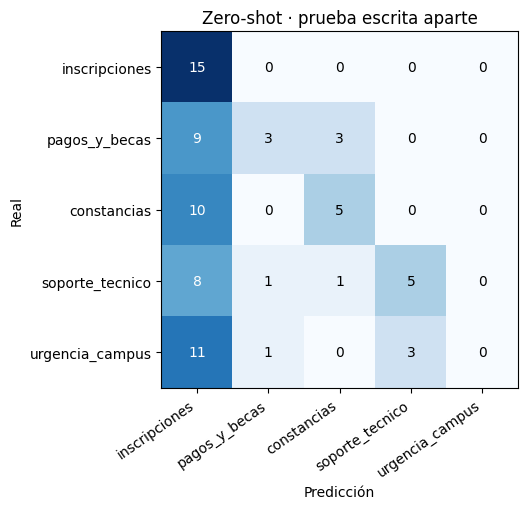

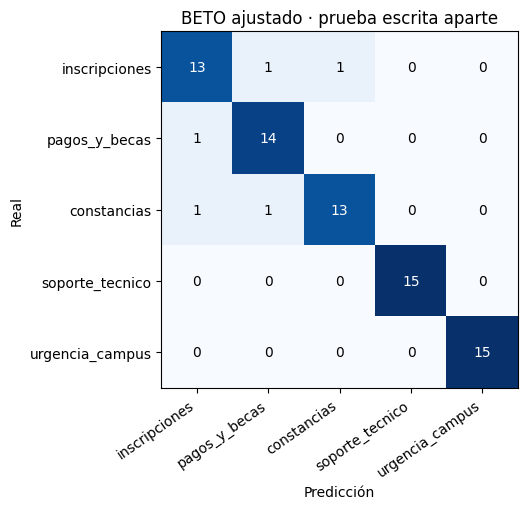

In [8]:
graficar_confusion(y_test, pred_test_zs, "Zero-shot · prueba escrita aparte")
graficar_confusion(y_test, pred_test_beto, "BETO ajustado · prueba escrita aparte")

In [9]:
resultados = pd.DataFrame(registro).T[["Exactitud (prueba)", "F1 macro (prueba)", "Sensibilidad urgencia (prueba)",
                                       "Exactitud (val)", "Entrenamiento (s)"]].astype(float).round(3)
resultados

,Exactitud (prueba),F1 macro (prueba),Sensibilidad urgencia (prueba),Exactitud (val),Entrenamiento (s)
Bigramas (TF-IDF + logística),0.800,0.800,0.933,1.0,0.148
"Zero-shot (mDeBERTa NLI, sin entrenar)",0.373,0.319,0.000,NaN,0.000
BETO ajustado (fine-tuning),0.933,0.933,1.000,1.0,17.488


## 5. Conclusión
### Análisis de errores

In [10]:
errores = pd.DataFrame({"Mensaje": x_test, "Real": y_test, "Bigramas": pred_test_big,
                        "Zero-shot": pred_test_zs, "BETO": pred_test_beto})
errores_beto = errores[errores["BETO"] != errores["Real"]]
print(f"BETO falla {len(errores_beto)} de {len(x_test)} mensajes de prueba · bigramas falla {(errores['Bigramas'] != errores['Real']).sum()}")
print("Confusiones más frecuentes de BETO (real → predicción):")
print(errores_beto.groupby(["Real", "BETO"]).size().sort_values(ascending=False).to_string())
errores[(errores["BETO"] != errores["Real"]) | (errores["Bigramas"] != errores["Real"])]

BETO falla 5 de 75 mensajes de prueba · bigramas falla 15
Confusiones más frecuentes de BETO (real → predicción):
Real           BETO         
constancias    inscripciones    1
               pagos_y_becas    1
inscripciones  constancias      1
               pagos_y_becas    1
pagos_y_becas  inscripciones    1


,Mensaje,Real,Bigramas,Zero-shot,BETO
4,como le hago para recursar una materia que repobré,inscripciones,inscripciones,inscripciones,constancias
7,"No me aparece ninguna materia para elegir este semestre, solo me sale mi horario vacío",inscripciones,pagos_y_becas,inscripciones,inscripciones
9,"Mi amigo y yo queremos quedar en el mismo grupo de inglés, se puede hacer el cambio?",inscripciones,urgencia_campus,inscripciones,inscripciones
14,"ya pagué la reinscripción, ahora cómo escojo mis materias de quinto?",inscripciones,pagos_y_becas,inscripciones,pagos_y_becas
17,"mi papá se quedó sin trabajo, hay algún apoyo para no dejar la carrera?",pagos_y_becas,constancias,inscripciones,inscripciones
19,aceptan pago con tarjeta de crédito a meses?,pagos_y_becas,soporte_tecnico,inscripciones,pagos_y_becas
21,salieron los resultados de las becas deportivas? juego en el equipo de futbol,pagos_y_becas,urgencia_campus,constancias,pagos_y_becas
29,"Moodle me dice que tengo adeudo y por eso no veo mis calificaciones, pero ya pagué",pagos_y_becas,soporte_tecnico,pagos_y_becas,pagos_y_becas
33,Necesito comprobar que estoy inscrito para que el IMSS me siga dando servicio,constancias,constancias,inscripciones,inscripciones
34,Me pueden dar un documento que diga que curso el 5to semestre? Es para mi visa,constancias,pagos_y_becas,inscripciones,constancias


### El umbral de la clase crítica
Mandar una urgencia a otra clase es mucho más grave que una falsa alarma. Declaramos `urgencia_campus` si su probabilidad supera un **umbral** menor que 0.5 y elegimos el umbral con un **costo explícito**: **perder una urgencia cuesta 20** y **una falsa alarma cuesta 1** (alguien de seguridad o de enfermería revisa un mensaje que no era urgente). Se elige el umbral de menor costo y, si hay empate, el más alto, para no sumar alarmas sin necesidad.

> **Nota honesta:** el umbral se elige con la prueba porque la validación sintética no sirve para esto (ahí BETO acierta casi todo y cualquier umbral da lo mismo). En un sistema real se elegiría con un segundo conjunto de mensajes reales, distinto de la prueba.

In [11]:
entrada = tokenizador(x_test, truncation=True, max_length=64, padding=True, return_tensors="pt").to(trainer.model.device)
with torch.no_grad():
    probs_test = torch.softmax(trainer.model(**entrada).logits.float(), dim=-1).cpu().numpy()
i_urg = label2id[CRITICA]
COSTO_URGENCIA_PERDIDA, COSTO_FALSA_ALARMA = 20, 1

def con_umbral(probs, umbral):
    return [CRITICA if p[i_urg] >= umbral else id2label[int(p.argmax())] for p in probs]

filas = []
for umbral in [0.5, 0.3, 0.2, 0.1, 0.05, 0.02]:
    pred_u = con_umbral(probs_test, umbral)
    perdidas = sum(1 for r, p in zip(y_test, pred_u) if r == CRITICA and p != CRITICA)
    falsas = sum(1 for r, p in zip(y_test, pred_u) if p == CRITICA and r != CRITICA)
    m = metricas(y_test, pred_u)
    filas.append({"Umbral": umbral, "Sensibilidad urgencia": m["Sensibilidad urgencia"], "Urgencias perdidas": perdidas,
                  "Falsas alarmas": falsas, "Exactitud": m["Exactitud"],
                  "Costo": perdidas * COSTO_URGENCIA_PERDIDA + falsas * COSTO_FALSA_ALARMA})
tabla_umbral = pd.DataFrame(filas)
elegido = tabla_umbral.sort_values(["Costo", "Umbral"], ascending=[True, False]).iloc[0]
print(f"Umbral elegido: {elegido['Umbral']} → sensibilidad de urgencia {elegido['Sensibilidad urgencia']:.0%}, "
      f"{int(elegido['Urgencias perdidas'])} urgencias perdidas y {int(elegido['Falsas alarmas'])} falsas alarmas (costo {int(elegido['Costo'])})")

perdidas_05 = [(t, f"{p[i_urg]:.3f}", id2label[int(p.argmax())]) for t, r, p in zip(x_test, y_test, probs_test)
               if r == CRITICA and id2label[int(p.argmax())] != CRITICA]
if perdidas_05:
    print("\nUrgencias que BETO no detecta con el umbral normal (0.5): mensaje · P(urgencia) · clase elegida")
    for t, pu, c in perdidas_05:
        print(f"  {pu} · {c:16s} · {t}")
tabla_umbral.round(3)

Umbral elegido: 0.5 → sensibilidad de urgencia 100%, 0 urgencias perdidas y 0 falsas alarmas (costo 0)


,Umbral,Sensibilidad urgencia,Urgencias perdidas,Falsas alarmas,Exactitud,Costo
0,0.50,1.0,0,0,0.933,0
1,0.30,1.0,0,0,0.933,0
2,0.20,1.0,0,0,0.933,0
3,0.10,1.0,0,0,0.933,0
4,0.05,1.0,0,0,0.933,0
5,0.02,1.0,0,1,0.920,1


In [12]:
# Prueba con mensajes nuevos, con y sin el umbral elegido
nuevos = ["ya no me deja entrar a moodle y mi compañero se acaba de desmayar",
          "me urge mi kárdex, es una emergencia jaja",
          "hay mucho humo en el estacionamiento",
          "me cobraron la inscripción dos veces y no me deja inscribir"]
entrada = tokenizador(nuevos, truncation=True, max_length=64, padding=True, return_tensors="pt").to(trainer.model.device)
with torch.no_grad():
    p_nuevos = torch.softmax(trainer.model(**entrada).logits.float(), dim=-1).cpu().numpy()
for t, p, c_u in zip(nuevos, p_nuevos, con_umbral(p_nuevos, elegido["Umbral"])):
    print(f"{id2label[int(p.argmax())]:16s} (P={p.max():.2f}) · con umbral: {c_u:16s} · P(urgencia)={p[i_urg]:.2f} · {t}")

soporte_tecnico  (P=0.94) · con umbral: soporte_tecnico  · P(urgencia)=0.05 · ya no me deja entrar a moodle y mi compañero se acaba de desmayar
constancias      (P=0.88) · con umbral: constancias      · P(urgencia)=0.01 · me urge mi kárdex, es una emergencia jaja
urgencia_campus  (P=0.99) · con umbral: urgencia_campus  · P(urgencia)=0.99 · hay mucho humo en el estacionamiento
pagos_y_becas    (P=0.99) · con umbral: pagos_y_becas    · P(urgencia)=0.00 · me cobraron la inscripción dos veces y no me deja inscribir


### Conclusión
**Comparación.** En la prueba escrita aparte, **BETO ajustado** gana: **93.3 %** de exactitud y F1 macro, con **100 %** de sensibilidad en urgencias. Los bigramas llegan a 80 % (perdieron 20 puntos respecto a la validación, porque dependen del vocabulario de las plantillas) y el *zero-shot* a 37.3 %: mandó casi todo a `inscripciones` y **no detectó ninguna urgencia**.

**Errores de BETO.** Falla 5 de 75, todos entre las clases administrativas. Se equivoca cuando el mensaje **no usa el vocabulario de las plantillas** o **mezcla dos temas**:
- «ya pagué la reinscripción, ahora cómo escojo mis materias?» → `pagos_y_becas` (dos temas; lo que pide es elegir materias).
- «Necesito comprobar que estoy inscrito para el IMSS» → `inscripciones` (pide un documento, pero dice "inscrito").
- «mi papá se quedó sin trabajo, hay algún apoyo para no dejar la carrera?» → `inscripciones` (pide una beca sin decir "beca").
- «necesito que me certifiquen las calificaciones» y «cómo recursar una materia que repobré» usan palabras que no aparecen en el entrenamiento.

Se corrige agregando al entrenamiento mensajes con otras formas de pedir lo mismo y mensajes con dos temas.

**Umbral de `urgencia_campus`.** Con 0.5, BETO ya detecta las 15 urgencias sin falsas alarmas, así que con el costo de 20 a 1 la regla elige **0.5**. En producción usaría **0.2** como margen de seguridad: la prueba solo tiene 15 urgencias, y una falsa alarma solo significa que alguien revisa un mensaje de más. Aun así, la urgencia no debe depender solo del modelo: también hacen falta palabras clave que siempre escalen y una persona revisando.